# Prédire la taille des resorts exclus du clustering

Ce notebook entraîne un modèle sur les tailles produites par `resort_size_classification.ipynb`, puis propose une taille pour les resorts qui ne possèdent pas toutes les mesures nécessaires au clustering principal.

Les prédictions sont **indicatives** : elles ne modifient aucune donnée en base. Les resorts Hors-catégorie restent déterminés par les seuils explicites du notebook de classification.

In [1]:
# À exécuter une seule fois si nécessaire.
# %pip install -r requirements.txt

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict


def find_project_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd / 'resort_sizing', cwd.parent):
        if (candidate / 'notebooks').is_dir() and (candidate / 'data').is_dir():
            return candidate
    raise RuntimeError(
        'Lancez ce notebook depuis SkiJo, resort_sizing ou resort_sizing/notebooks.'
    )


PROJECT_ROOT = find_project_root()
INPUT_PATH = PROJECT_ROOT / 'data' / 'imported' / 'prediction_features.csv'
LABELS_PATH = PROJECT_ROOT / 'data' / 'outputs' / 'classified_resorts.csv'
if not INPUT_PATH.exists():
    raise FileNotFoundError(
        'Données absentes : data/imported/prediction_features.csv doit être présent dans le projet.'
    )
if not LABELS_PATH.exists():
    raise FileNotFoundError(
        'Exécutez d’abord resort_size_classification.ipynb pour créer classified_resorts.csv.'
    )

sns.set_theme(style='whitegrid', context='notebook')
TAILLE_ORDER = ['Petite', 'Moyenne', 'Intermédiaire', 'Grande']
FEATURES = ['denivele_station_m', 'pistes_km', 'remontees_count', 'pistes_count']
FEATURE_LABELS = {
    'denivele_station_m': 'Dénivelé de la station (m)',
    'pistes_km': 'Pistes (km)',
    'remontees_count': 'Remontées (hors tapis si détaillées)',
    'pistes_count': 'Nombre de pistes',
}
RANDOM_STATE = 42


## Caractéristiques disponibles

Le nombre de remontées provient du détail `resort_lifts`, hors tapis, quand celui-ci est disponible. Sinon, le total consolidé `lifts_count` sert de repli pour ne pas perdre les resorts ayant des caractéristiques mais aucun détail de remontées.

In [3]:
caracteristiques = pd.read_csv(INPUT_PATH)
labels = pd.read_csv(LABELS_PATH)[['slug', 'taille']]
dataset = caracteristiques.merge(labels, on='slug', how='left', validate='one_to_one')
dataset.head()


,station,slug,season,denivele_station_m,pistes_km,pistes_count,remontees_count,source_remontees_count,taille
0,Abondance,abondance,2026-27,1508.0,15.0,13.0,8.0,détail hors tapis,Intermédiaire
1,Abriès,abries-queyras,2026-27,900.0,33.0,16.0,7.0,détail hors tapis,Intermédiaire
2,Aiguille du Midi (Chamonix),aiguille-du-midi-chamonix,2026-27,2807.0,NaN,NaN,5.0,détail hors tapis,NaN
3,Aiguilles,aiguilles,2026-27,160.0,3.0,5.0,1.0,détail hors tapis,Petite
4,Aillon-le-Jeune,aillon-le-jeune,2026-27,312.0,8.0,NaN,5.0,détail hors tapis,Moyenne


In [4]:
# Les Hors-catégorie sont exclus de l'entraînement : leur classe est fondée sur des seuils,
# et quatre exemples ne suffisent pas pour apprendre une classe robuste.
entrainement = dataset.loc[
    dataset['taille'].isin(TAILLE_ORDER) & dataset[FEATURES].notna().all(axis=1)
].copy()
a_predire = dataset.loc[
    dataset['taille'].isna() & dataset[FEATURES].notna().all(axis=1)
].copy()
sans_prediction = dataset.loc[
    dataset['taille'].isna() & ~dataset[FEATURES].notna().all(axis=1)
].copy()

print(f'Entraînement : {len(entrainement)} resorts étiquetés.')
print(f'Prédictions possibles : {len(a_predire)} resorts.')
print(f'Non prédits faute de caractéristiques : {len(sans_prediction)} resorts.')

Entraînement : 156 resorts étiquetés.
Prédictions possibles : 77 resorts.
Non prédits faute de caractéristiques : 44 resorts.


## Validation du modèle

Une validation croisée à cinq plis estime l'accord entre la taille connue et la taille prédite. Elle évite de mesurer le modèle sur les mêmes exemples que ceux utilisés pour son apprentissage.

Exactitude : 84.0%
Exactitude équilibrée : 84.2%


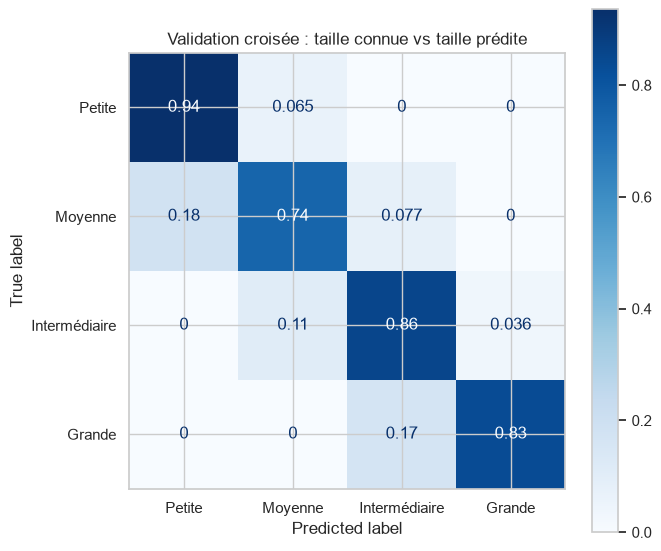

In [5]:
X_train = entrainement[FEATURES]
y_train = entrainement['taille']
model = RandomForestClassifier(
    n_estimators=500, min_samples_leaf=2, class_weight='balanced_subsample',
    random_state=RANDOM_STATE, n_jobs=-1,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_predictions = cross_val_predict(model, X_train, y_train, cv=cv, n_jobs=-1)
print(f'Exactitude : {accuracy_score(y_train, cv_predictions):.1%}')
print(f'Exactitude équilibrée : {balanced_accuracy_score(y_train, cv_predictions):.1%}')

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_train, cv_predictions, labels=TAILLE_ORDER, normalize='true', cmap='Blues', ax=ax,
)
ax.set_title('Validation croisée : taille connue vs taille prédite')
plt.tight_layout()
plt.show()

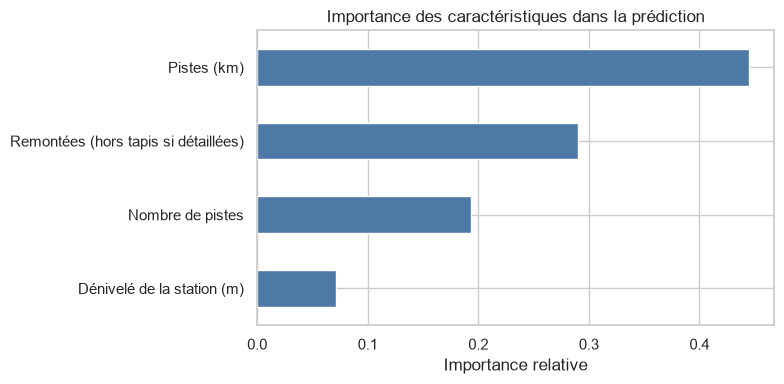

Pistes (km)                             0.445166
Remontées (hors tapis si détaillées)    0.290099
Nombre de pistes                        0.193526
Dénivelé de la station (m)              0.071209
dtype: float64

In [6]:
model.fit(X_train, y_train)
importances = (pd.Series(model.feature_importances_, index=FEATURES)
               .sort_values(ascending=True)
               .rename(index=FEATURE_LABELS))
fig, ax = plt.subplots(figsize=(8, 4))
importances.plot.barh(color='#4E79A7', ax=ax)
ax.set(title='Importance des caractéristiques dans la prédiction', xlabel='Importance relative', ylabel='')
plt.tight_layout()
plt.show()
importances.sort_values(ascending=False)

## Prédictions proposées

La confiance est la probabilité maximale renvoyée par la forêt aléatoire. Une faible confiance signifie que le resort ressemble à plusieurs tailles connues : la prédiction doit alors être relue avant tout usage éditorial.

In [7]:
if a_predire.empty:
    predictions = a_predire.assign(taille_predite=pd.Series(dtype='object'), confiance=pd.Series(dtype='float'))
else:
    probabilities = model.predict_proba(a_predire[FEATURES])
    predictions = a_predire.copy()
    predictions['taille_predite'] = model.classes_[probabilities.argmax(axis=1)]
    predictions['confiance'] = probabilities.max(axis=1)

predictions['a_revoir'] = predictions['confiance'] < 0.60
predictions['confiance'] = predictions['confiance'].round(6)
resultats = predictions[[
    'station', 'slug', *FEATURES, 'source_remontees_count',
    'taille_predite', 'confiance', 'a_revoir',
]].sort_values(['a_revoir', 'confiance', 'station'], ascending=[False, True, True])
output_path = PROJECT_ROOT / 'data' / 'outputs' / 'predicted_resort_sizes.csv'
output_path.parent.mkdir(parents=True, exist_ok=True)
resultats.to_csv(output_path, index=False)
print(f'Export créé : {output_path.relative_to(PROJECT_ROOT)}')
resultats


Export créé : data/outputs/predicted_resort_sizes.csv


,station,slug,denivele_station_m,pistes_km,remontees_count,pistes_count,source_remontees_count,taille_predite,confiance,a_revoir
224,Morillon,morillon,1800.0,145.0,4.0,3.0,faits consolidés,Intermédiaire,0.481794,True
280,Saint Véran,saint-veran,1000.0,36.0,13.0,27.0,faits consolidés,Grande,0.519417,True
49,Chaillol,chaillol,550.0,13.0,8.0,12.0,faits consolidés,Moyenne,0.550919,True
283,Sixt-Fer-à-Cheval,sixt-fer-a-cheval,800.0,145.0,4.0,5.0,faits consolidés,Intermédiaire,0.556882,True
314,Villard-Reculas,villard-reculas,1830.0,20.0,8.0,10.0,faits consolidés,Intermédiaire,0.557664,True
...,...,...,...,...,...,...,...,...,...,...
255,Risoul,risoul,1100.0,185.0,36.0,105.0,faits consolidés,Grande,0.999455,False
265,Saint-François-Longchamp,saint-francois-longchamp,1100.0,165.0,16.0,103.0,faits consolidés,Grande,0.999455,False
57,Châtel,chatel,1000.0,120.0,56.0,68.0,faits consolidés,Grande,1.000000,False
188,Les Gets,les-gets,1002.0,117.0,55.0,77.0,faits consolidés,Grande,1.000000,False
